# 3. Distribución, anomalías y cambios de régimen

El análisis numérico utiliza el periodo completo de desarrollo **2000–2021**. Los ajustes de escaladores y modelos se realizan dentro de cada fold.

Los precios están en COP nominales por kWh. Se comparan escala original y log1p, como diagnóstico retrospectivo de desarrollo; los parámetros de una transformación predictiva se estiman sólo con el entrenamiento de cada fold. Los umbrales IQR/MAD son diagnósticos explícitos y no reglas de eliminación.

Las rupturas se buscan sobre la media diaria en log1p estandarizada con desarrollo: segmentación binaria determinista, segmentos de al menos 90 días, candidatos cada 7 días, umbral de ganancia SSE de $3\log n$ y un máximo de ocho rupturas. El procedimiento identifica cambios exploratorios de media para el análisis de regímenes.


In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from IPython.display import Markdown, display
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal, stats

In [2]:
TARGET = 'precio_bolsa_cop_kwh'
EDA_SPLITS = {'train': (2000, 2017), 'validation': (2018, 2021), 'test': (2022, 2025)}
SPLITS = EDA_SPLITS
TIME = 'timestamp_start_colombia'
RESULTS = ROOT / 'results'
PIPELINE_DEFAULTS = {'method': 'split_train_val_forwardChaining', 'n_splits': 5, 'development_start': '2000-01-01T00:00:00-05:00', 'validation_start': '2018-01-01T00:00:00-05:00', 'development_end_exclusive': '2022-01-01T00:00:00-05:00', 'test_start': '2022-01-01T00:00:00-05:00', 'test_end_exclusive': '2026-01-01T00:00:00-05:00', 'lookback_hours': 168, 'horizon_hours': 24, 'stride_hours': 24, 'hourly_release_lag_hours': 24, 'hydrology_release_lag_days': 2, 'include_calendar': True, 'seed': 11037, 'availability_scenario': 'retrospective_assumed_release_lags'}
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.4), 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18, 'axes.prop_cycle': plt.cycler(color=['#245b8d', '#d17a32', '#2b8c77', '#8c5da8', '#9a4949'])})
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def decision(preprocess, architecture, validation, risk):
    display(Markdown('### Implicaciones del análisis\n\n' + '\n'.join(('- **' + a + ':** ' + b for a, b in [('Preprocesamiento', preprocess), ('Arquitectura', architecture), ('Validación', validation), ('Riesgos', risk)]))))

In [4]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [5]:
def load_numeric(split='train', table='hourly', *, allow_test=False):
    if split not in SPLITS:
        raise ValueError('Unknown split')
    if split == 'test' and (not allow_test):
        raise PermissionError('El EDA no puede consultar valores de prueba.')
    a, b = SPLITS[split]
    folder = 'hourly' if table == 'hourly' else 'hydrology'
    frame = pd.concat([pd.read_csv(ROOT / f'data/numeric/{folder}/{year}.csv.gz') for year in range(a, b + 1)], ignore_index=True)
    if table == 'hourly':
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame[TIME], utc=True)).tz_convert('America/Bogota')
    else:
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame['date'])).tz_localize('America/Bogota')
    frame.index.name = 'tiempo_colombia'
    return frame

In [6]:
def load_development_data(table='hourly'):
    return pd.concat([load_numeric('train', table=table), load_numeric('validation', table=table)]).sort_index()

In [7]:
def pipeline_config(overrides=None):
    config = dict(PIPELINE_DEFAULTS)
    if overrides:
        unknown = set(overrides) - set(config)
        if unknown:
            raise ValueError('Opciones desconocidas: ' + str(sorted(unknown)))
        config.update(overrides)
    for field in ['n_splits', 'lookback_hours', 'horizon_hours', 'stride_hours']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 1:
            raise ValueError('Se requiere un entero positivo: ' + field)
    for field in ['hourly_release_lag_hours', 'hydrology_release_lag_days']:
        if not isinstance(config[field], int) or isinstance(config[field], bool) or config[field] < 0:
            raise ValueError('Rezago inválido: ' + field)
    if config['hydrology_release_lag_days'] < 1:
        raise ValueError('La hidrología diaria requiere al menos el cierre del día.')
    for field in ['development_start', 'validation_start', 'development_end_exclusive', 'test_start', 'test_end_exclusive']:
        if pd.Timestamp(config[field]).tzinfo is None:
            raise ValueError('Se requiere zona horaria: ' + field)
    if config['method'] != 'split_train_val_forwardChaining':
        raise ValueError('Método no autorizado')
    if pd.Timestamp(config['test_start']) != pd.Timestamp(PIPELINE_DEFAULTS['test_start']) or config['test_end_exclusive'] != PIPELINE_DEFAULTS['test_end_exclusive']:
        raise ValueError('El periodo de prueba está congelado.')
    if not pd.Timestamp(config['development_start']) < pd.Timestamp(config['validation_start']) < pd.Timestamp(config['development_end_exclusive']) <= pd.Timestamp(config['test_start']):
        raise ValueError('Cortes temporales inválidos')
    if config['stride_hours'] % 24:
        raise ValueError('Los orígenes deben conservar el paso diario.')
    return config

In [8]:
def load_pipeline_config(path=None):
    path = ROOT / 'configs/training_pipeline.json' if path is None else path
    return pipeline_config(json.loads(path.read_text(encoding='utf-8')))

In [9]:
def load_eda_development(table='hourly'):
    """Desarrollo completo; no cambia las particiones que usa el entrenamiento."""
    config = load_pipeline_config()
    frame = load_development_data(table)
    if len(frame) and frame.index.max() >= pd.Timestamp(config['test_start']):
        raise PermissionError('La fuente contiene fechas de prueba.')
    start = pd.Timestamp(config['development_start'])
    end = pd.Timestamp(config['development_end_exclusive'])
    frame = frame.loc[(frame.index >= start) & (frame.index < end)]
    if frame.empty or frame.index.max() >= pd.Timestamp(config['test_start']):
        raise PermissionError('El EDA sólo admite desarrollo anterior a prueba.')
    return frame

In [10]:
def development_daily():
    frame = load_eda_development()
    return (frame, frame[TARGET].resample('D').mean())

In [11]:
def figure(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [12]:
frame, daily = development_daily()
y = frame[TARGET]
desc = y.describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).to_frame('COP/kWh')
desc.loc['asimetría'] = stats.skew(y)
desc.loc['curtosis_exceso'] = stats.kurtosis(y)
table(desc, 'distribucion_precio_desarrollo')

,COP/kWh
count,1.9286e+05
mean,135.82
std,137.05
min,21.531
1%,29.318
5%,37.321
25%,65.316
50%,93.246
75%,160.46
95%,362.01


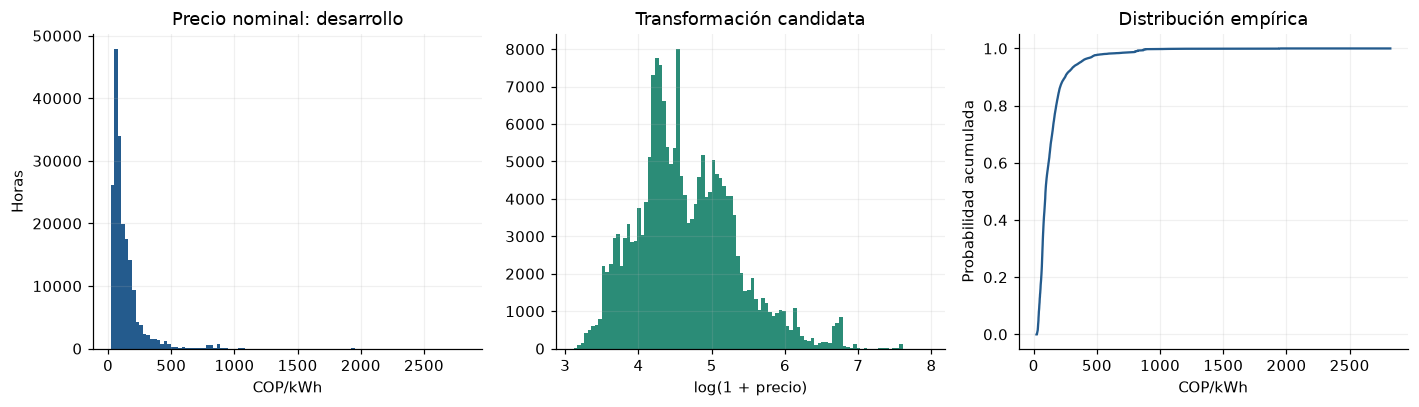

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].hist(y, bins=100, color='#245b8d')
axes[0].set(xlabel='COP/kWh', ylabel='Horas', title='Precio nominal: desarrollo')
axes[1].hist(np.log1p(y), bins=100, color='#2b8c77')
axes[1].set(xlabel='log(1 + precio)', title='Transformación candidata')
q = np.sort(y)
axes[2].plot(q, np.arange(1, len(q) + 1) / len(q))
axes[2].set(xlabel='COP/kWh', ylabel='Probabilidad acumulada', title='Distribución empírica')
figure(fig, 'distribucion_precio')

In [14]:
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
med = y.median()
mad = (y - med).abs().median()
upper = q3 + 1.5 * iqr
robust = med + 6 * 1.4826 * mad
out = pd.DataFrame({'umbral_superior': [upper, robust], 'horas_mayores': [(y > upper).sum(), (y > robust).sum()]}, index=['IQR 1,5', 'MAD 6'])
table(out, 'umbrales_anomalias_desarrollo')

,umbral_superior,horas_mayores
"IQR 1,5",303.18,13407
MAD 6,446.92,6158


In [15]:
diagnostic = (y - med).abs()
influence = []
for label, mask in [('Mayor que Q99', y > y.quantile(0.99)), ('Mayor que umbral IQR', y > upper)]:
    influence.append(dict(grupo=label, fraccion_horas=float(mask.mean()), fraccion_error_absoluto=float(diagnostic[mask].sum() / diagnostic.sum()), fraccion_error_cuadratico=float((diagnostic[mask] ** 2).sum() / (diagnostic ** 2).sum())))
table(pd.DataFrame(influence).set_index('grupo'), 'influencia_anomalias_perdida_desarrollo')

,fraccion_horas,fraccion_error_absoluto,fraccion_error_cuadratico
grupo,,,
Mayor que Q99,0.0099863,0.12128,0.42609
Mayor que umbral IQR,0.069515,0.40637,0.83037


In [16]:
display(Markdown('La influencia se mide respecto de la mediana de desarrollo como centro diagnóstico, no como pronóstico evaluado. Cuantifica cuánto pesan los extremos en errores absolutos y cuadrados sin consultar prueba ni eliminar esos episodios.'))

La influencia se mide respecto de la mediana de desarrollo como centro diagnóstico, no como pronóstico evaluado. Cuantifica cuánto pesan los extremos en errores absolutos y cuadrados sin consultar prueba ni eliminar esos episodios.

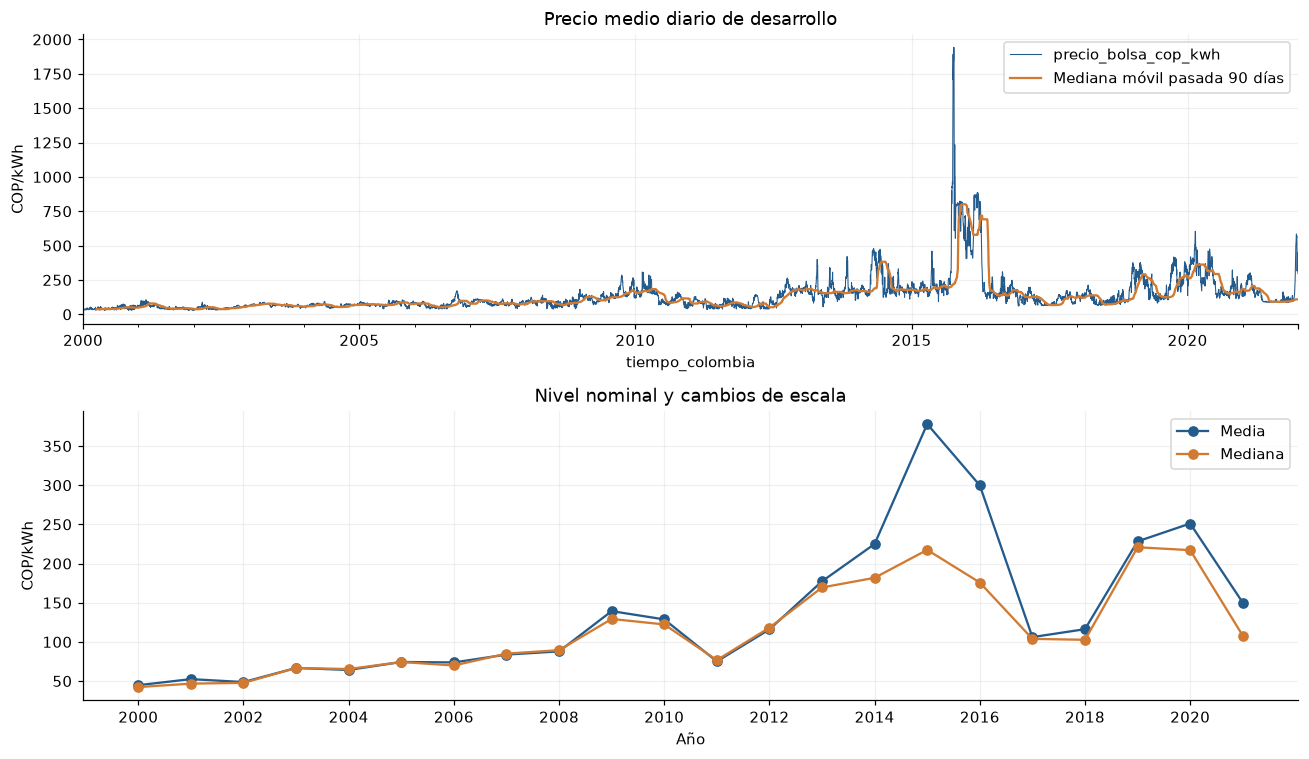

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
daily.plot(ax=axes[0], lw=0.7)
daily.rolling(90, min_periods=90).median().plot(ax=axes[0], lw=1.5, label='Mediana móvil pasada 90 días')
axes[0].set(ylabel='COP/kWh', title='Precio medio diario de desarrollo')
axes[0].legend()
yearly = frame.assign(anio=frame.index.year).groupby('anio')[TARGET].agg(['mean', 'median', 'std', 'max'])
yearly[['mean', 'median']].plot(ax=axes[1], marker='o')
axes[1].set(ylabel='COP/kWh', xlabel='Año', title='Nivel nominal y cambios de escala')
axes[1].set_xticks(yearly.index[::2])
axes[1].set_xticklabels([str(y) for y in yearly.index[::2]])
axes[1].legend(['Media', 'Mediana'])
figure(fig, 'precio_regimenes')

In [18]:
table(yearly, 'precio_anual_desarrollo')

,mean,median,std,max
anio,,,,
2000,44.738,42.297,15.743,96.138
2001,52.471,46.728,20,118.07
2002,48.728,47.684,11.978,138.55
2003,66.726,66.624,10.915,148
2004,64.17,65.371,12.822,189.9
2005,74.359,74.333,15.345,186.75
2006,73.794,69.887,29.437,281.23
2007,83.775,85.002,18.712,154.7
2008,87.875,89.425,33.351,438.84


In [19]:
z = np.log1p(daily.to_numpy())
z = (z - z.mean()) / z.std()
cuts = []
pending = [(0, len(z))]
while pending and len(cuts) < 8:
    left, right = pending.pop(0)
    if right - left < 180:
        continue
    x = z[left:right]
    cs = np.r_[0, np.cumsum(x)]
    n = len(x)
    idx = np.arange(90, n - 89, 7)
    gain = cs[idx] ** 2 / idx + (cs[-1] - cs[idx]) ** 2 / (n - idx) - cs[-1] ** 2 / n
    best = int(np.argmax(gain))
    if gain[best] > 3 * np.log(len(z)):
        cut = left + int(idx[best])
        cuts.append((cut, float(gain[best])))
        pending.extend([(left, cut), (cut, right)])
breaks = pd.DataFrame([dict(fecha=daily.index[i].date(), ganancia_sse=g) for i, g in sorted(cuts)])
table(breaks, 'rupturas_exploratorias_desarrollo')

,fecha,ganancia_sse
0,2002-10-04,170.89
1,2006-09-01,612.36
2,2008-12-18,178.51
3,2010-11-18,147.85
4,2012-07-27,3702.3
5,2015-09-17,666.44
6,2016-04-28,356.92
7,2018-12-12,300.35


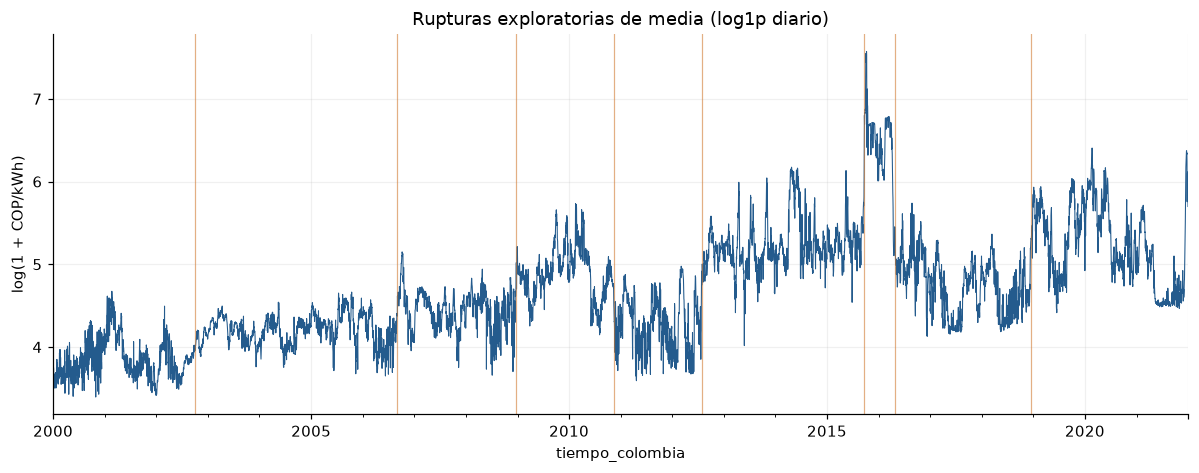

In [20]:
fig, ax = plt.subplots()
np.log1p(daily).plot(ax=ax, lw=0.7)
for i, g in cuts:
    ax.axvline(daily.index[i], color='#d17a32', alpha=0.6, lw=0.8)
ax.set(title='Rupturas exploratorias de media (log1p diario)', ylabel='log(1 + COP/kWh)')
figure(fig, 'rupturas_desarrollo')

In [21]:
decision(f'Comparar escala robusta/log1p con escala en COP, ajustadas sólo con train. IQR superior={upper:.2f}; no eliminar picos por ser extremos.', 'Capacidad para cambios de nivel y colas; considerar salida robusta o probabilística, sin inferir que NLP ya ayuda.', 'Mantener episodios extremos en evaluación futura y reportar error por régimen; evitar métricas porcentuales cerca de cero.', 'Precios nominales de años distintos no son poder adquisitivo constante. Una ruptura estadística no identifica su causa; STL centrada y segmentación usan futuro dentro de train y no son atributos operativos.')

### Implicaciones del análisis

- **Preprocesamiento:** Comparar escala robusta/log1p con escala en COP, ajustadas sólo con train. IQR superior=303.18; no eliminar picos por ser extremos.
- **Arquitectura:** Capacidad para cambios de nivel y colas; considerar salida robusta o probabilística, sin inferir que NLP ya ayuda.
- **Validación:** Mantener episodios extremos en evaluación futura y reportar error por régimen; evitar métricas porcentuales cerca de cero.
- **Riesgos:** Precios nominales de años distintos no son poder adquisitivo constante. Una ruptura estadística no identifica su causa; STL centrada y segmentación usan futuro dentro de train y no son atributos operativos.